# Financial Data Analysis: Microsoft, Tesla, Apple (FY2023–FY2025)
**Purpose:** extract key 10-K metrics and analyse trends to inform an AI-powered financial chatbot.

**Data source:** SEC EDGAR 10-K filings. All figures in **USD millions**.

> ⚠️ **Before submitting:** verify every number in `financial_data.csv` against the actual 10-K (Item 8 – Consolidated Statements of Income, Balance Sheets, Cash Flows). Tesla FY2025 assets, liabilities and operating cash flow are left blank for you to fill in. The code below handles missing values.

**Methodology**
1. Manually extract Total Revenue, Net Income, Total Assets, Total Liabilities, Operating Cash Flow.
2. Load into pandas, compute YoY growth, margins and balance-sheet ratios.
3. Compare companies and summarise findings.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
pd.options.display.float_format = '{:,.1f}'.format

## 1. Load the data

In [2]:
df = pd.read_csv('financial_data.csv')
df = df.sort_values(['Company','Year']).reset_index(drop=True)
df

,Company,Fiscal Period,Year,Total Revenue,Net Income,Total Assets,Total Liabilities,Operating Cash Flow,Data Note
0,Apple,"FY2023 (Sep 30, 2023)",2023,383285,96995,"352,583.0","290,437.0","110,543.0",Verified-from-memory
1,Apple,"FY2024 (Sep 28, 2024)",2024,391035,93736,"364,980.0","308,030.0","118,254.0",Verified-from-memory
2,Apple,"FY2025 (Sep 27, 2025)",2025,416161,112010,"359,241.0","285,508.0","111,482.0",Verify against 10-K
3,Microsoft,"FY2023 (Jun 30, 2023)",2023,211915,72361,"411,976.0","205,753.0","87,582.0",Verified-from-memory
4,Microsoft,"FY2024 (Jun 30, 2024)",2024,245122,88136,"512,163.0","243,686.0","118,548.0",Verified-from-memory
5,Microsoft,"FY2025 (Jun 30, 2025)",2025,281724,101832,"619,003.0","275,524.0","136,162.0",Verify against 10-K
6,Tesla,"FY2023 (Dec 31, 2023)",2023,96773,14974,"106,618.0","43,009.0","13,256.0",Verified-from-memory
7,Tesla,"FY2024 (Dec 31, 2024)",2024,97690,7091,"122,070.0","48,390.0","14,923.0",Verified-from-memory
8,Tesla,"FY2025 (Dec 31, 2025)",2025,94827,3794,NaN,NaN,NaN,"Revenue/NI verify; fill assets, liabilities, C..."


In [3]:
df.info()
print('\nMissing values per column:')
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Company              9 non-null      str    
 1   Fiscal Period        9 non-null      str    
 2   Year                 9 non-null      int64  
 3   Total Revenue        9 non-null      int64  
 4   Net Income           9 non-null      int64  
 5   Total Assets         8 non-null      float64
 6   Total Liabilities    8 non-null      float64
 7   Operating Cash Flow  8 non-null      float64
 8   Data Note            9 non-null      str    
dtypes: float64(3), int64(3), str(3)
memory usage: 780.0 bytes

Missing values per column:
Company                0
Fiscal Period          0
Year                   0
Total Revenue          0
Net Income             0
Total Assets           1
Total Liabilities      1
Operating Cash Flow    1
Data Note              0
dtype: int64


## 2. Year-over-year growth
Using `groupby('Company').pct_change()` so growth is never computed across company boundaries.

In [4]:
metrics = ['Total Revenue','Net Income','Total Assets','Total Liabilities','Operating Cash Flow']
for m in metrics:
    df[f'{m} Growth (%)'] = df.groupby('Company')[m].pct_change() * 100

growth_cols = [f'{m} Growth (%)' for m in metrics]
df[['Company','Year'] + growth_cols]

,Company,Year,Total Revenue Growth (%),Net Income Growth (%),Total Assets Growth (%),Total Liabilities Growth (%),Operating Cash Flow Growth (%)
0,Apple,2023,NaN,NaN,NaN,NaN,NaN
1,Apple,2024,2.0,-3.4,3.5,6.1,7.0
2,Apple,2025,6.4,19.5,-1.6,-7.3,-5.7
3,Microsoft,2023,NaN,NaN,NaN,NaN,NaN
4,Microsoft,2024,15.7,21.8,24.3,18.4,35.4
5,Microsoft,2025,14.9,15.5,20.9,13.1,14.9
6,Tesla,2023,NaN,NaN,NaN,NaN,NaN
7,Tesla,2024,0.9,-52.6,14.5,12.5,12.6
8,Tesla,2025,-2.9,-46.5,NaN,NaN,NaN


## 3. Profitability and balance-sheet ratios

In [5]:
df['Net Margin (%)'] = df['Net Income'] / df['Total Revenue'] * 100
df['Equity'] = df['Total Assets'] - df['Total Liabilities']
df['Liabilities / Assets (%)'] = df['Total Liabilities'] / df['Total Assets'] * 100
df['Cash Conversion (OCF / NI)'] = df['Operating Cash Flow'] / df['Net Income']
df[['Company','Year','Net Margin (%)','Equity','Liabilities / Assets (%)','Cash Conversion (OCF / NI)']]

,Company,Year,Net Margin (%),Equity,Liabilities / Assets (%),Cash Conversion (OCF / NI)
0,Apple,2023,25.3,"62,146.0",82.4,1.1
1,Apple,2024,24.0,"56,950.0",84.4,1.3
2,Apple,2025,26.9,"73,733.0",79.5,1.0
3,Microsoft,2023,34.1,"206,223.0",49.9,1.2
4,Microsoft,2024,36.0,"268,477.0",47.6,1.3
5,Microsoft,2025,36.1,"343,479.0",44.5,1.3
6,Tesla,2023,15.5,"63,609.0",40.3,0.9
7,Tesla,2024,7.3,"73,680.0",39.6,2.1
8,Tesla,2025,4.0,NaN,NaN,NaN


## 4. Aggregations across companies

In [6]:
summary = df.groupby('Company')[['Total Revenue','Net Income','Net Margin (%)','Operating Cash Flow']].mean()
summary

,Total Revenue,Net Income,Net Margin (%),Operating Cash Flow
Company,,,,
Apple,"396,827.0","100,913.7",25.4,"113,426.3"
Microsoft,"246,253.7","87,443.0",35.4,"114,097.3"
Tesla,"96,430.0","8,619.7",8.9,"14,089.5"


In [7]:
def cagr(s):
    s = s.dropna()
    n = len(s) - 1
    return ((s.iloc[-1] / s.iloc[0]) ** (1 / n) - 1) * 100 if n > 0 else float('nan')

cagr_table = df.groupby('Company')[['Total Revenue','Net Income']].agg(cagr)
cagr_table.columns = ['Revenue CAGR (%)','Net Income CAGR (%)']
cagr_table

,Revenue CAGR (%),Net Income CAGR (%)
Company,,
Apple,4.2,7.5
Microsoft,15.3,18.6
Tesla,-1.0,-49.7


## 5. Visualisations

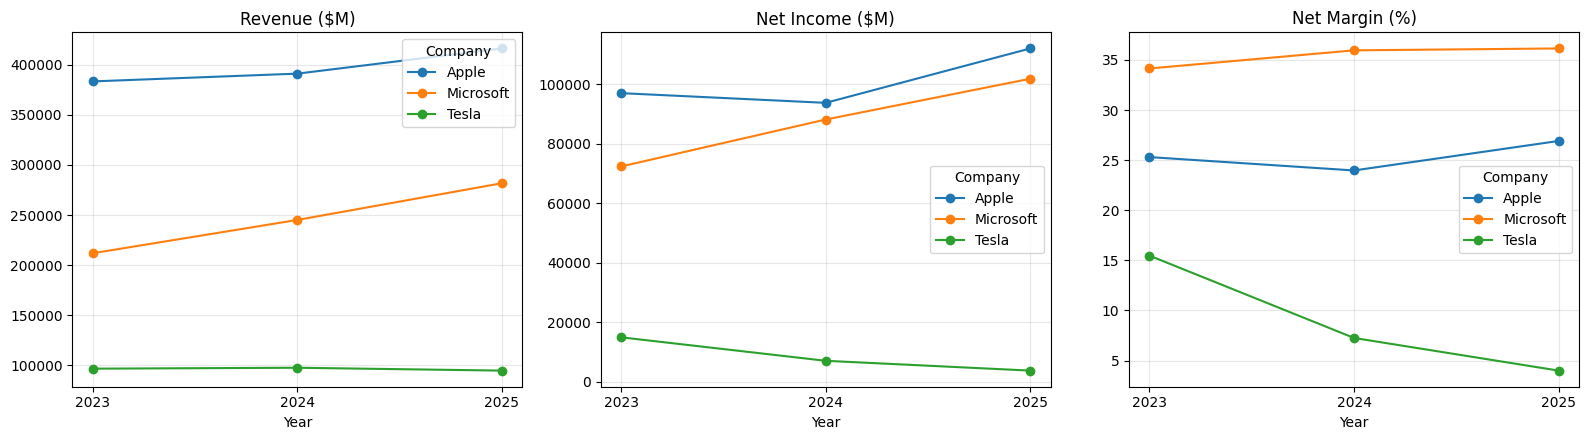

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (col, title) in zip(axes, [('Total Revenue','Revenue ($M)'),('Net Income','Net Income ($M)'),('Net Margin (%)','Net Margin (%)')]):
    p = df.pivot(index='Year', columns='Company', values=col)
    p.plot(marker='o', ax=ax, title=title)
    ax.set_xticks(p.index)
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

## 6. Summary of findings

Revisit these once you've confirmed the data; the numbers quoted reflect the values in the CSV.

- **Microsoft** is the steadiest grower: revenue rose from ~$212B (FY23) to ~$282B (FY25), roughly 15% CAGR, with net income growing even faster (~19% CAGR) as margins expanded to ~36%. Operating cash flow grew about 25% a year, reflecting cloud/AI scale.
- **Apple** is the largest by revenue (~$416B in FY25) but grows slowly (~4% CAGR). Net income dipped in FY24 and rebounded in FY25; net margin sits around 24–27%. It carries the highest liabilities-to-assets ratio (~80%), largely from buybacks funded with debt.
- **Tesla** shows the most volatility: revenue was flat to slightly down (~$97B → ~$95B) while net income fell sharply (~$15.0B → ~$3.8B), compressing net margin from ~15% to ~4% amid price cuts and rising costs. Its balance sheet is the least leveraged (liabilities ≈ 40% of assets in FY23–24).
- **Cash conversion** (OCF / NI) is above 1 in nearly every year (the exception is Tesla FY23, ~0.9), which is typical for companies with large non-cash charges such as depreciation and stock-based compensation. Tesla's jumps in FY24 because net income is depressed.

### Implications for a financial chatbot
1. **Fiscal calendars differ** (Microsoft: June, Apple: September, Tesla: December). The bot must label periods by fiscal year-end date and warn when comparing across companies.
2. **Normalised metrics** (margins, growth, ratios) are more useful for comparison than raw dollars.
3. **Data quality matters**: net income vs. net income attributable to common stockholders, restated figures and missing values (like Tesla FY25 here) require validation and source citations.
4. **Ground answers in filings**: the chatbot should cite the 10-K item/page for every figure to avoid hallucinated numbers.
5. **Context over numbers**: growth rates need explanations (pricing, product cycles, AI investment), which come from MD&A text, not just tables.